# Extended Data Fig. 5

Redraws all panels of Extended Data Fig. 5 from the figshare source data:

* `Wilhelm_SourceData_ED_Fig5a.parquet` / `.csv` — spectral angles of the unmodified hold-out set by sequence similarity
  to the training set, with n, median peptide length and quartiles
* `Wilhelm_SourceData_ED_Fig5b.parquet` / `.csv` — per-peptide absolute iRT prediction errors on unseen PTMs, with box
  statistics and n
* `Wilhelm_SourceData_ED_Fig5c.parquet` / `.csv` — spectral angles on unseen PTMs per model, with n and quartiles

Data access: files are downloaded from the figshare article given by `FIGSHARE_ARTICLE_ID` (config cell below or environment variable; set `FIGSHARE_TOKEN` while the article is private) into `./data`, or read from a local copy of the deposit if the environment variable `SOURCE_DATA_DIR` points to it. Panels are saved to `regenerated_panels/ED_Fig5/` (PDF and PNG).

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'ED_Fig5'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(name):
    for ext in ('pdf', 'png'):
        plt.savefig(FIG_DIR / f'{name}.{ext}', dpi=300, bbox_inches='tight')


pd.set_option('display.max_colwidth', None)
readme('ED_Fig5')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Extended Data Fig. 5,a,NaN,Wilhelm_SourceData_ED_Fig5a.parquet; Wilhelm_SourceData_ED_Fig5a.csv,"Spectral angle of each HCD spectrum of the unmodified hold-out set (Prosit-22PTM) by sequence similarity to the training set; n, median peptide length and quartiles in Wilhelm_SourceData_ED_Fig5a.csv.",NaN
1,Extended Data Fig. 5,b,NaN,Wilhelm_SourceData_ED_Fig5b.parquet; Wilhelm_SourceData_ED_Fig5b.csv,"Absolute iRT prediction error of each peptide carrying an unseen PTM, per model (Prosit-22PTM: predictions of Fig. 3e; DeepLC: calibrated per PTM package by robust LOESS); box statistics and n in Wilhelm_SourceData_ED_Fig5b.csv.",NaN
2,Extended Data Fig. 5,c,NaN,Wilhelm_SourceData_ED_Fig5c.parquet; Wilhelm_SourceData_ED_Fig5c.csv,Spectral angle of each HCD spectrum per unseen PTM and model; n and quartiles in Wilhelm_SourceData_ED_Fig5c.csv.,NaN


## a — spectral angle stratified by sequence similarity between hold-out and training peptides
Split violins (`bw_method=0.2`, `inner='quartile'`): left, `>=70%` vs all other spectra; middle, each other similarity
group vs the full `>=70%` group; right, as middle, restricted to `in_length_matched_subsample`. Numbers above the violins:
median peptide length (aa).

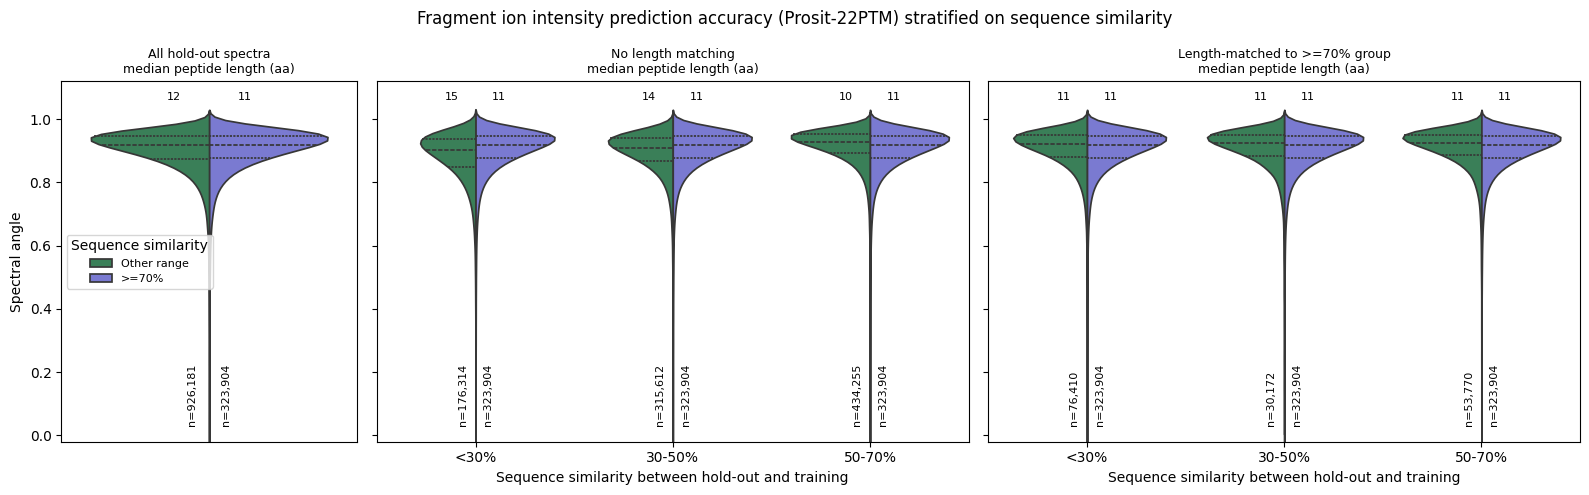

,subplot,similarity_group (x),violin_half,n_spectra,median_peptide_length_aa,Q1_spectral_angle,median_spectral_angle,Q3_spectral_angle
0,left,all,Other range (<70%),926181,12,0.875722,0.917969,0.946137
1,left,all,>=70%,323904,11,0.877276,0.919469,0.947827
2,middle,<30%,Other range,176314,15,0.849985,0.901450,0.936334
3,middle,<30%,>=70%,323904,11,0.877276,0.919469,0.947827
4,middle,30-50%,Other range,315612,14,0.867330,0.909870,0.939390
5,middle,30-50%,>=70%,323904,11,0.877276,0.919469,0.947827
6,middle,50-70%,Other range,434255,10,0.892883,0.928882,0.952529
7,middle,50-70%,>=70%,323904,11,0.877276,0.919469,0.947827
8,right,<30%,Other range,76410,11,0.880265,0.920820,0.948815
9,right,<30%,>=70%,323904,11,0.877276,0.919469,0.947827


In [3]:
a = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig5a.parquet'),
                    columns=['sequence_similarity_to_training', 'in_length_matched_subsample',
                             'peptide_length_aa', 'spectral_angle'])
sim = a['sequence_similarity_to_training']
ref = a[sim == '>=70%']
GROUPS = ['<30%', '30-50%', '50-70%']
pal = {'Other range': '#2E8B57', '>=70%': '#6B6BE0'}
violin_kw = dict(y='spectral_angle', hue='half', hue_order=['Other range', '>=70%'], split=True,
                 bw_method=0.2, inner='quartile', palette=pal)


def halves(groups, matched):
    parts = []
    for g in groups:
        o = a[(sim != '>=70%')] if g == 'all' else a[sim == g]
        if matched:
            o = o[o['in_length_matched_subsample']]
        parts += [o.assign(x=g, half='Other range'), ref.assign(x=g, half='>=70%')]
    return pd.concat(parts, ignore_index=True)


fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 2, 2]}, sharey=True)
for ax, (groups, matched, title) in zip(axes, [(['all'], False, 'All hold-out spectra'),
                                                (GROUPS, False, 'No length matching'),
                                                (GROUPS, True, 'Length-matched to >=70% group')]):
    d = halves(groups, matched)
    sns.violinplot(data=d, x='x', order=groups, ax=ax, legend=ax is axes[0], **violin_kw)
    stats = d.groupby(['x', 'half'])
    n, ln = stats.size(), stats['peptide_length_aa'].median()
    for i, g in enumerate(groups):
        for half, dx, ha in [('Other range', -0.04, 'right'), ('>=70%', 0.04, 'left')]:
            ax.text(i + dx, 0.03, f"n={n[(g, half)]:,}", rotation=90, ha=ha, va='bottom', fontsize=8)
            ax.text(i + dx * 3, 1.06, f"{ln[(g, half)]:.0f}", ha='center', fontsize=8)
    ax.set_title(f"{title}\nmedian peptide length (aa)", fontsize=9)
    ax.set_xlabel('' if groups == ['all'] else 'Sequence similarity between hold-out and training')
    ax.set_ylabel('Spectral angle')
    ax.set_ylim(-0.02, 1.12)
    if groups == ['all']:
        ax.set_xticks([])
axes[0].legend(title='Sequence similarity', loc='center left', fontsize=8)
fig.suptitle('Fragment ion intensity prediction accuracy (Prosit-22PTM) stratified on sequence similarity')
plt.tight_layout()
save('ED_Fig5a')
plt.show()
table('ED_Fig5a')

## b — absolute iRT prediction error, Prosit-22PTM vs DeepLC (unseen PTMs)
Box plot (Tukey whiskers, 1.5 x IQR, no fliers) of `abs_delta_iRT` of the peptides carrying the PTM (`carries_ptm`), per
PTM and model. Prosit-22PTM: predictions as in Fig. 3e, without further calibration; DeepLC: predicted iRT calibrated to
observed iRT per PTM package by robust LOESS (frac 0.3, 3 robustness iterations). n = unique peptides carrying the PTM (`n_unique_peptides_carrying_PTM (n label)`).

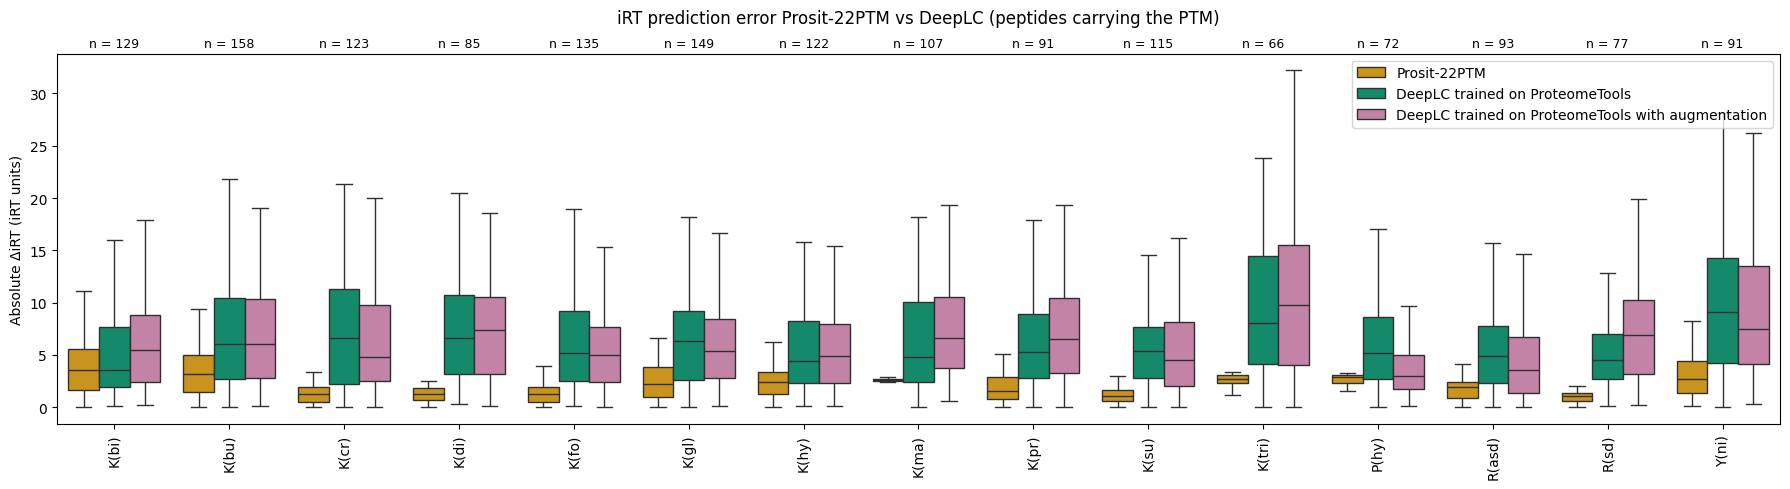

,PTM,model,n_unique_peptides_carrying_PTM (n label),lower_whisker_abs_dIRT,Q1_abs_dIRT,median_abs_dIRT,Q3_abs_dIRT,upper_whisker_abs_dIRT,calibration,median_abs_dIRT_uncalibrated,median_abs_dIRT_linear_calibration
0,K(bi),Prosit-22PTM,129,0.017988,1.659738,3.535604,5.600163,11.083302,none (as Fig. 3e),3.535604,NaN
1,K(bi),DeepLC trained on ProteomeTools,129,0.078569,1.934394,3.549727,7.674738,16.012470,"LOESS (frac 0.3, 3 robustness iterations)",12.126167,3.874081
2,K(bi),DeepLC trained on ProteomeTools with augmentation,129,0.252416,2.392277,5.446182,8.794455,17.915091,"LOESS (frac 0.3, 3 robustness iterations)",15.092937,5.994868
3,K(bu),Prosit-22PTM,158,0.067471,1.454009,3.173592,5.043461,9.438420,none (as Fig. 3e),3.173592,NaN
4,K(bu),DeepLC trained on ProteomeTools,158,0.014958,2.721903,6.054104,10.449766,21.858922,"LOESS (frac 0.3, 3 robustness iterations)",20.934999,6.579215
5,K(bu),DeepLC trained on ProteomeTools with augmentation,158,0.090947,2.773539,6.072947,10.334035,19.022829,"LOESS (frac 0.3, 3 robustness iterations)",22.068779,6.825024
6,K(cr),Prosit-22PTM,123,0.036224,0.529082,1.234656,1.920130,3.356273,none (as Fig. 3e),1.234656,NaN
7,K(cr),DeepLC trained on ProteomeTools,123,0.005156,2.262632,6.664521,11.268398,21.303393,"LOESS (frac 0.3, 3 robustness iterations)",26.837517,6.476022
8,K(cr),DeepLC trained on ProteomeTools with augmentation,123,0.031327,2.491204,4.819464,9.777952,20.042270,"LOESS (frac 0.3, 3 robustness iterations)",28.130045,7.128519
9,K(di),Prosit-22PTM,85,0.060324,0.697186,1.229127,1.839704,2.507574,none (as Fig. 3e),1.229127,NaN


In [4]:
b = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig5b.parquet')).query('carries_ptm')
order = list(dict.fromkeys(b['PTM']))
models = ['Prosit-22PTM', 'DeepLC trained on ProteomeTools', 'DeepLC trained on ProteomeTools with augmentation']
fig, ax = plt.subplots(figsize=(18, 5))
sns.boxplot(data=b, x='PTM', y='abs_delta_iRT', hue='model', order=order, hue_order=models,
            palette=['#E69F00', '#009E73', '#CC79A7'], showfliers=False, ax=ax)
n = table('ED_Fig5b').groupby('PTM')['n_unique_peptides_carrying_PTM (n label)'].first()
top = ax.get_ylim()[1]
for i, p in enumerate(order):
    ax.text(i, top * 1.01, f"n = {n[p]}", ha='center', va='bottom', fontsize=9)
ax.set_xlabel('')
ax.set_ylabel('Absolute ΔiRT (iRT units)')
ax.set_title('iRT prediction error Prosit-22PTM vs DeepLC (peptides carrying the PTM)', pad=22)
ax.legend(title='', loc='upper right')
plt.xticks(rotation=90)
plt.tight_layout()
save('ED_Fig5b')
plt.show()
table('ED_Fig5b')

## c — spectral angle, Prosit vs AlphaPeptDeep (unseen PTMs, HCD)
Split violins (seaborn defaults: Scott bandwidth, `cut=2`; `inner='quart'`) of `spectral_angle` per PTM and model; left,
models without augmentation; right, with augmentation. n labels from `n_label` in `Wilhelm_SourceData_ED_Fig5c.csv`.

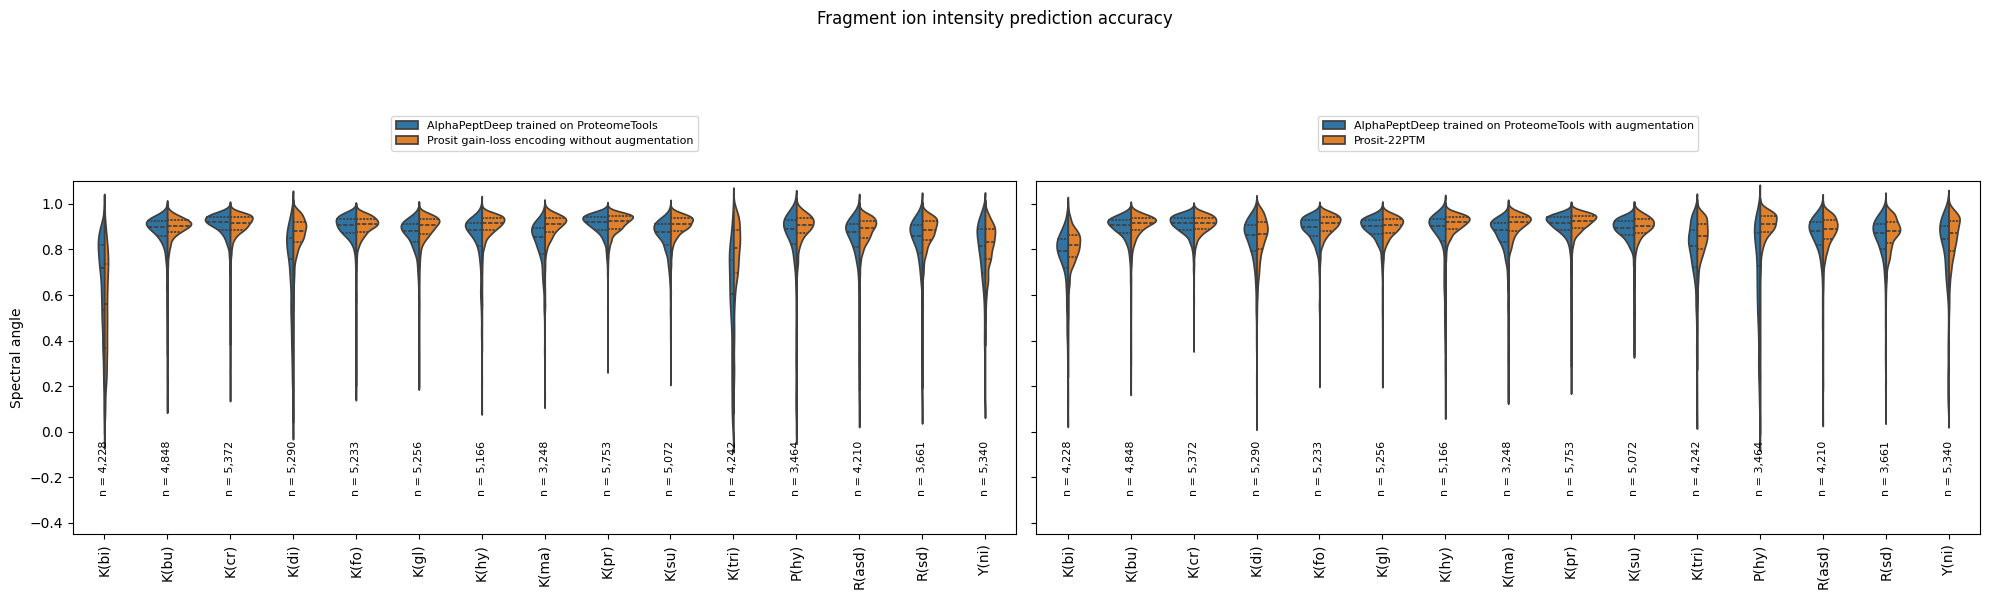

,subplot,PTM,model,n_label,n_spectra,Q1_spectral_angle,median_spectral_angle,Q3_spectral_angle
0,left,K(bi),Prosit gain-loss encoding without augmentation,4228,4228,0.365637,0.561409,0.735222
1,left,K(bi),AlphaPeptDeep trained on ProteomeTools,4228,4595,0.534407,0.717604,0.820278
2,right,K(bi),Prosit-22PTM,4228,4228,0.766864,0.817843,0.863015
3,right,K(bi),AlphaPeptDeep trained on ProteomeTools with augmentation,4228,4595,0.719970,0.794245,0.845274
4,left,K(bu),Prosit gain-loss encoding without augmentation,4848,4848,0.876370,0.905033,0.927292
5,left,K(bu),AlphaPeptDeep trained on ProteomeTools,4848,5215,0.859213,0.899462,0.925741
6,right,K(bu),Prosit-22PTM,4848,4848,0.883655,0.917462,0.937867
7,right,K(bu),AlphaPeptDeep trained on ProteomeTools with augmentation,4848,5215,0.870474,0.905739,0.930288
8,left,K(cr),Prosit gain-loss encoding without augmentation,5372,5372,0.886469,0.917824,0.942400
9,left,K(cr),AlphaPeptDeep trained on ProteomeTools,5372,5372,0.886481,0.919275,0.942028


In [5]:
c = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig5c.parquet'))
summ = table('ED_Fig5c')
order = list(dict.fromkeys(c['PTM']))
pairs = {'left': ['AlphaPeptDeep trained on ProteomeTools', 'Prosit gain-loss encoding without augmentation'],
         'right': ['AlphaPeptDeep trained on ProteomeTools with augmentation', 'Prosit-22PTM']}
fig, axes = plt.subplots(1, 2, figsize=(20, 5.5), sharey=True)
for ax, (sub, hue_order) in zip(axes, pairs.items()):
    d = c[c['subplot'] == sub]
    sns.violinplot(data=d, x='PTM', y='spectral_angle', hue='model', order=order, hue_order=hue_order,
                   split=True, inner='quart', palette=['#1F77B4', '#FF7F0E'], ax=ax)
    nlab = summ[summ['subplot'] == sub].groupby('PTM')['n_label'].first()
    for i, p in enumerate(order):
        ax.text(i, -0.04, f"n = {nlab[p]:,}", rotation=90, ha='center', va='top', fontsize=8)
    ax.set_ylim(-0.45, 1.1)
    ax.set_xlabel('')
    ax.set_ylabel('Spectral angle')
    ax.legend(title='', loc='upper center', bbox_to_anchor=(0.5, 1.2), fontsize=8)
    ax.tick_params(axis='x', rotation=90)
fig.suptitle('Fragment ion intensity prediction accuracy', y=1.08)
plt.tight_layout()
save('ED_Fig5c')
plt.show()
table('ED_Fig5c')